# FPSO em 6 graus de liberdade com o Capytaine
### Tutorial passo a passo · PNV3425 – Projeto de Sistemas Oceânicos

Na aula anterior resolvemos o **Exercício 6** (RAO de heave do FPSO de 250 × 40 × 12 m) pelo modelo analítico e pelo Capytaine, só em heave. Agora vamos montar, do zero, um modelo do mesmo casco **nos seis graus de liberdade**: todos os dados do problema (frequências, direções de onda, massa, inércias, amortecimento externo) são **vetores e matrizes criados aqui no notebook**. O único arquivo de entrada é a malha do casco, `ship_low.gdf`.

**O que você vai aprender**

1. Definir os dados de um problema de comportamento no mar como vetores e matrizes.
2. Importar uma malha no formato GDF e separar o casco da superfície livre interna (tampa).
3. Montar um corpo flutuante com 6 graus de liberdade, com matriz de massa e rigidez hidrostática.
4. Resolver os problemas de radiação e difração e interpretar massa adicional, amortecimento e RAO.
5. **Inserir um amortecimento externo no roll** e ver o efeito no RAO.
6. Comparar os RAOs dos seis graus de liberdade em diferentes direções de onda.

**Antes de começar**

- Pacotes: `pip install capytaine matplotlib xarray pandas` (testado com Capytaine 3.0).
- Coloque este notebook e o arquivo `ship_low.gdf` na mesma pasta.
- Tempo de execução: o cálculo completo (60 frequências × 25 direções × 6 graus de liberdade) leva **cerca de 5 minutos** em 2 núcleos. Com `RAPIDO = True` (célula seguinte) ele cai para 1 a 2 minutos, com um terço das frequências e só cinco direções. O resultado é salvo em disco e reaproveitado nas próximas execuções.

## 0. Preparação do ambiente

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import capytaine as cpt

cpt.set_logging('ERROR')         # 'INFO' mostra mensagens detalhadas do cálculo
print('Capytaine', cpt.__version__)

# ---------------- opções do tutorial
RAPIDO = False                   # True: menos frequências e direções (teste rápido)
REUSAR = True                    # reaproveita o resultado salvo, se existir

ARQ_MALHA = Path('fpso_low.gdf')
ARQ_RESULTADO = Path('capytaine_fpso_6gl_v2.nc')
assert ARQ_MALHA.exists(), f'Malha não encontrada: {ARQ_MALHA.resolve()}'

# graus de liberdade, unidades e cores usadas nos gráficos
DOFS = ['Surge', 'Sway', 'Heave', 'Roll', 'Pitch', 'Yaw']
ROT = {'Roll', 'Pitch', 'Yaw'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

Capytaine 3.0.0


## 1. Dados do problema: vetores e matrizes

Tudo o que define o problema, exceto a geometria, está nesta seção. Mude qualquer valor e rode o notebook de novo para estudar o efeito.

### 1.1 Casco, água e centro de gravidade

In [2]:
# casco prismático do Exercício 6
L, B, T = 250.0, 40.0, 12.0            # comprimento, boca e calado [m]
RHO = 1025.0                           # densidade da água [kg/m³]
G = 9.80665                            # gravidade [m/s²]

VOL = L * B * T                        # volume deslocado [m³]
MASSA = RHO * VOL                      # massa = deslocamento [kg]  (123.000 t)

# centro de gravidade: no plano de simetria, na meia-nau e na linha d'água (KG = T)
KG = 12.0                              # altura do CG acima da quilha [m]
CG = (0.0, 0.0, KG - T)                # coordenadas do CG no sistema da malha [m] (z = 0 na linha d'água)
print(f'∇ = {VOL:.0f} m³,  M = {MASSA / 1e3:.0f} t,  CG = {CG} m')

∇ = 120000 m³,  M = 123000 t,  CG = (0.0, 0.0, 0.0) m


### 1.2 Matriz de massa a partir dos raios de giração

A inércia de rotação de um navio é dada por I = M·k², com k o **raio de giração** em torno de cada eixo. Valores típicos para cascos de navio:

| Movimento | Raio de giração | Valor usado |
|---|---|---|
| Roll (eixo x) | k_xx ≈ 0,30 a 0,40 B | 0,35 B = 14 m |
| Pitch (eixo y) | k_yy ≈ 0,24 a 0,26 L | 0,25 L = 62,5 m |
| Yaw (eixo z) | k_zz ≈ 0,25 a 0,30 L | 0,25 L = 62,5 m |

Com o CG na origem do sistema de rotação, a matriz de massa 6 × 6 é diagonal.

In [3]:
k_xx, k_yy, k_zz = 0.35 * B, 0.25 * L, 0.25 * L          # raios de giração [m]

matriz_massa = np.diag([MASSA, MASSA, MASSA,
                        MASSA * k_xx**2, MASSA * k_yy**2, MASSA * k_zz**2])

pd.DataFrame({'massa / inércia': np.diag(matriz_massa),
              'unidade': ['kg'] * 3 + ['kg·m²'] * 3}, index=DOFS).style.format({'massa / inércia': '{:.4e}'})

,massa / inércia,unidade
Surge,1.2300e+08,kg
Sway,1.2300e+08,kg
Heave,1.2300e+08,kg
Roll,2.4108e+10,kg·m²
Pitch,4.8047e+11,kg·m²
Yaw,4.8047e+11,kg·m²


### 1.3 Frequências e direções de onda

- **Frequências**: 60 valores entre 0,01 e 1,55 rad/s (períodos de 4 s a mais de 600 s). Três pontos de baixa frequência e, a partir de 0,15 rad/s, passo constante de 0,025 rad/s.
- **Direções**: de 0° a 360°, de 15° em 15° (25 valores). β = 0° é a onda propagando no sentido +x (da popa para a proa), β = 90° no sentido +y (mar de través) e β = 180° no sentido −x.

In [4]:
omegas = np.concatenate([[0.01, 0.05, 0.10], np.arange(0.15, 1.55 + 1e-9, 0.025)])   # rad/s
betas = np.arange(0.0, 360.0 + 1e-9, 15.0)                                           # graus

if RAPIDO:
    omegas = omegas[::3]
    betas = np.array([0.0, 45.0, 90.0, 135.0, 180.0])

print(f'{len(omegas)} frequências: {omegas.min():.2f} a {omegas.max():.2f} rad/s '
      f'(T de {2 * np.pi / omegas.max():.1f} s a {2 * np.pi / omegas.min():.0f} s)')
print(f'{len(betas)} direções: {betas.min():.0f}° a {betas.max():.0f}°')

60 frequências: 0.01 a 1.55 rad/s (T de 4.1 s a 628 s)
25 direções: 0° a 360°


## 2. Malha: importando o arquivo GDF

O arquivo `ship_low.gdf` descreve a superfície do casco por painéis planos quadrilaterais (formato GDF, comum em programas de método dos painéis). Ele tem dois tipos de painel:

- **casco** – a superfície molhada da caixa (fundo, costados e extremidades);
- **superfície livre interna** – painéis em z = 0, dentro da linha d'água.

No Capytaine, a superfície interna é a **tampa** (`lid_mesh`) do corpo; ela melhora a solução em altas frequências. Basta separar os painéis com centro em z = 0.

In [5]:
malha_gdf = cpt.load_mesh(ARQ_MALHA, file_format='gdf')
zc = malha_gdf.faces_centers[:, 2]
casco = malha_gdf.extract_faces(np.where(np.abs(zc) > 1e-6)[0], name='casco')
tampa = malha_gdf.extract_faces(np.where(np.abs(zc) <= 1e-6)[0], name='tampa')

print(f'Painéis no arquivo  : {malha_gdf.nb_faces}')
print(f'  casco             : {casco.nb_faces}')
print(f'  superfície interna: {tampa.nb_faces}')
print(f'Volume deslocado    : {casco.disp_volume:.0f} m³   (L·B·T = {VOL:.0f} m³)')
print(f'Área de linha d’água: {casco.waterplane_area:.0f} m²   (L·B = {L * B:.0f} m²)')
print(f'Centro de carena    : {np.round(casco.center_of_buoyancy, 3)} m   (KB = T/2 = {T / 2} m)')

Painéis no arquivo  : 4360
  casco             : 2760
  superfície interna: 1600
Volume deslocado    : 120000 m³   (L·B·T = 120000 m³)
Área de linha d’água: 10000 m²   (L·B = 10000 m²)
Centro de carena    : [-0. -0. -6.] m   (KB = T/2 = 6.0 m)


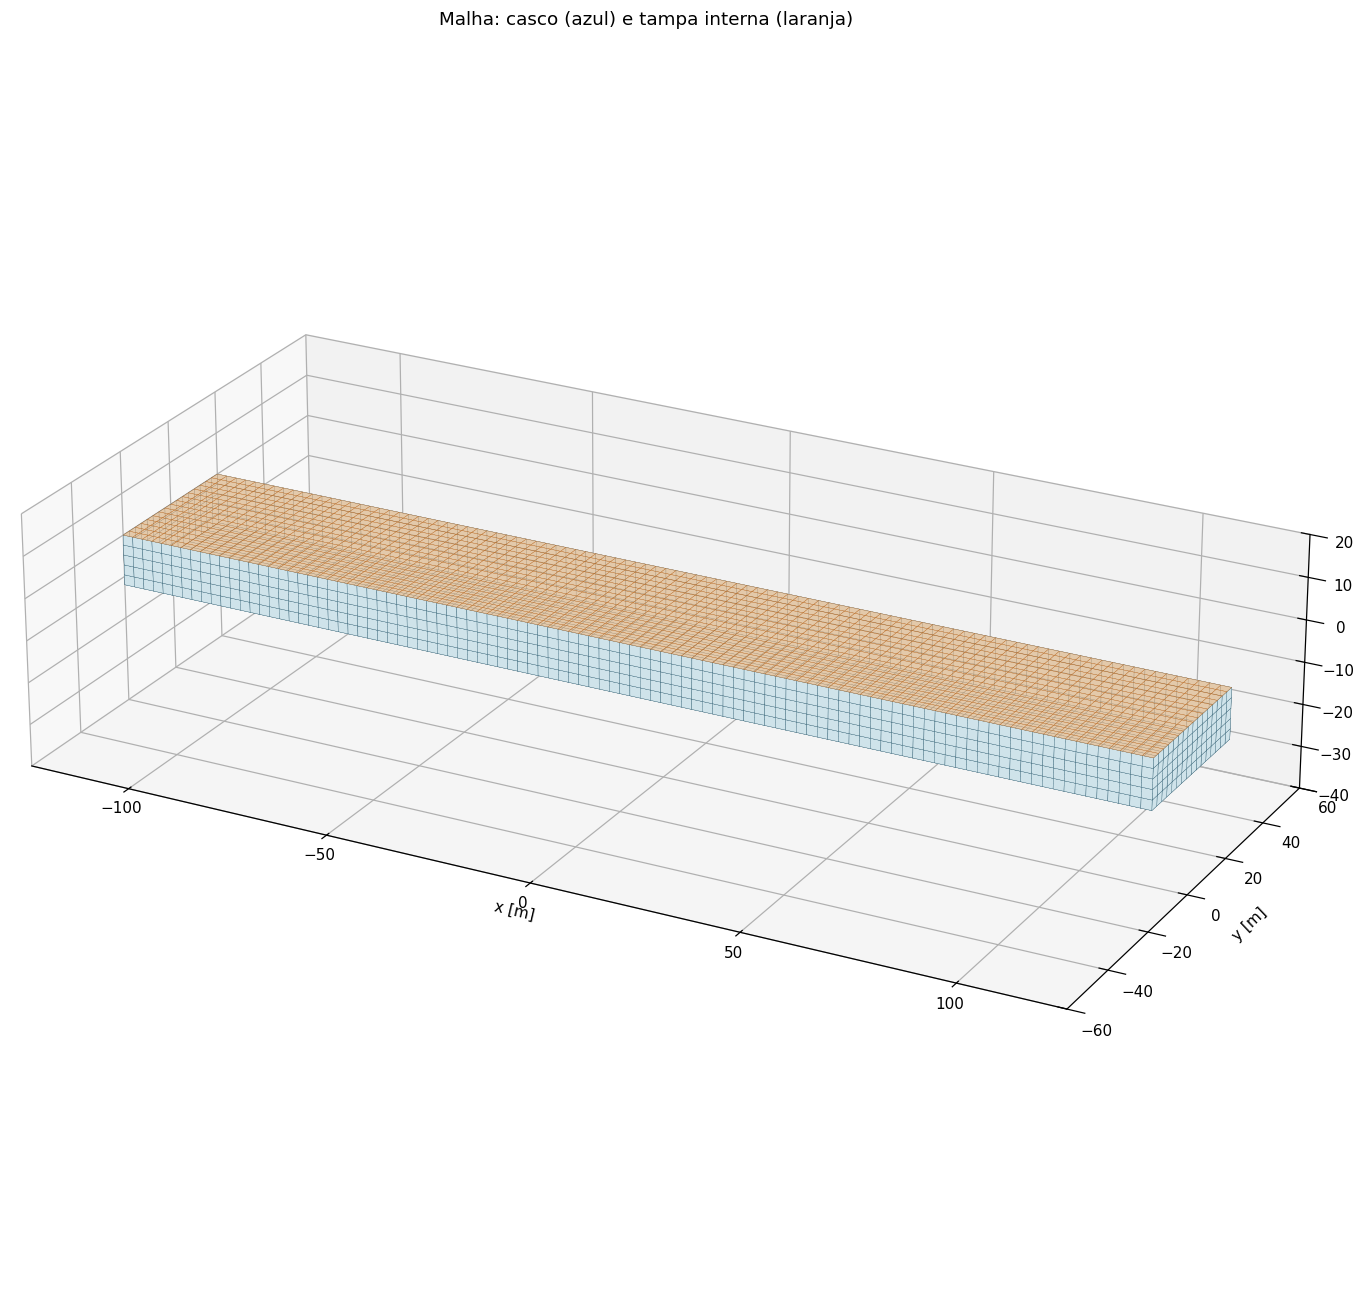

In [7]:
def desenha_malha(ax, malha, face, borda, alpha=1.0):
    ax.add_collection3d(Poly3DCollection(malha.vertices[malha.faces], facecolor=face,
                                         edgecolor=borda, linewidths=0.2, alpha=alpha))

fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(111, projection='3d')
desenha_malha(ax, casco, '#CFE3EA', '#1D4E63')
desenha_malha(ax, tampa, '#F2B880', '#B5651D', alpha=0.6)
ax.set_xlim(-125, 125); ax.set_ylim(-60, 60); ax.set_zlim(-40, 20)
ax.set_box_aspect((250, 120, 60)); ax.view_init(elev=24, azim=-62)
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_zlabel('z [m]')
ax.set_title('Malha: casco (azul) e tampa interna (laranja)')
plt.show()

**Tamanho dos painéis.** Os painéis têm cerca de 2,5 a 3 m. A regra prática é ter pelo menos 6 a 8 painéis por comprimento de onda na maior frequência: com ω = 1,55 rad/s, λ = 2πg/ω² ≈ 26 m, ou seja, cerca de 9 painéis por onda.

## 3. Corpo flutuante com 6 graus de liberdade

Três escolhas definem o corpo:

1. **Graus de liberdade**: `cpt.rigid_body_dofs()` cria os seis movimentos de corpo rígido (Surge, Sway, Heave, Roll, Pitch, Yaw).
2. **Centro de rotação**: as rotações são medidas em torno do CG.
3. **Massa e rigidez**: a matriz de massa é a da seção 1.2; a rigidez hidrostática é calculada pelo Capytaine a partir da malha, da massa e do CG.

In [9]:
corpo = cpt.FloatingBody(
    mesh=casco, lid_mesh=tampa,
    dofs=cpt.rigid_body_dofs(rotation_center=CG),
    center_of_mass=CG,
    name='FPSO')

corpo.inertia_matrix = corpo.add_dofs_labels_to_matrix(matriz_massa)
corpo.hydrostatic_stiffness = corpo.compute_hydrostatic_stiffness(rho=RHO, g=G)
print('Graus de liberdade:', list(corpo.dofs))

Graus de liberdade: ['Surge', 'Sway', 'Heave', 'Roll', 'Pitch', 'Yaw']


**Verificação com as fórmulas da hidrostática de uma caixa:**

$$C_{33} = \rho g L B, \qquad C_{44} = \rho g \nabla\, \overline{GM}_T, \qquad C_{55} = \rho g \nabla\, \overline{GM}_L$$

$$\overline{GM}_T = KB + \frac{B^2}{12\,T} - KG, \qquad \overline{GM}_L = KB + \frac{L^2}{12\,T} - KG$$

In [10]:
KB = T / 2
GMt = KB + B**2 / (12 * T) - KG
GMl = KB + L**2 / (12 * T) - KG
C_cap = corpo.hydrostatic_stiffness.values
analitico = [RHO * G * L * B, RHO * G * VOL * GMt, RHO * G * VOL * GMl]
tab = pd.DataFrame({'Capytaine (malha)': [C_cap[2, 2], C_cap[3, 3], C_cap[4, 4]], 'fórmula': analitico},
                   index=['C33 [N/m]', 'C44 [N·m/rad]', 'C55 [N·m/rad]'])
tab['diferença [%]'] = 100 * (tab['Capytaine (malha)'] / tab['fórmula'] - 1)
print(f'GMt = {GMt:.2f} m,  GMl = {GMl:.1f} m')
tab.style.format({'Capytaine (malha)': '{:.4e}', 'fórmula': '{:.4e}', 'diferença [%]': '{:+.2f}'})

GMt = 5.11 m,  GMl = 428.0 m


,Capytaine (malha),fórmula,diferença [%]
C33 [N/m],1.0052e+08,1.0052e+08,+0.00
C44 [N·m/rad],6.1128e+09,6.1651e+09,-0.85
C55 [N·m/rad],5.1624e+11,5.1629e+11,-0.01


A pequena diferença em C₄₄ (cerca de 1%) vem da integração numérica sobre os painéis: o momento de inércia da área de linha d'água é calculado com um ponto por painel, o que subestima ∫y² dA quando a boca tem poucos painéis (14). Ela diminui com painéis menores. Nos passos seguintes usamos a rigidez da malha, coerente com o cálculo hidrodinâmico.

## 4. Matriz de teste e solução BEM

A matriz de teste é um `xarray.Dataset` vazio cujas **coordenadas** listam todos os casos a resolver. Para cada frequência o Capytaine monta:

- 6 problemas de **radiação** (um por grau de liberdade) → massa adicional e amortecimento;
- 1 problema de **difração** por direção de onda → força de excitação.

**Formulação.** O Capytaine oferece duas formulações do problema de contorno: a *indireta* (padrão, distribuição de fontes na superfície) e a *direta* (o potencial é a incógnita, pelo teorema de Green). Aqui usamos a direta, `method='direct'`. Comparar as duas fica como exercício no final.

In [ ]:
matriz_teste = xr.Dataset(coords={
    'omega': omegas,                         # rad/s
    'wave_direction': np.radians(betas),     # rad (0 = propagação em +x)
    'radiating_dof': list(corpo.dofs),
    'water_depth': [np.inf],                 # águas profundas
    'rho': RHO,
    'g': G,
})
n_prob = len(omegas) * (len(corpo.dofs) + len(betas))
print(f'{len(omegas)} frequências × ({len(corpo.dofs)} radiação + {len(betas)} difração) = {n_prob} problemas')

In [11]:
if REUSAR and ARQ_RESULTADO.exists() and not RAPIDO:
    ds = cpt.io.xarray.merge_complex_values(xr.open_dataset(ARQ_RESULTADO))
    print(f'Resultado lido de {ARQ_RESULTADO} (apague o arquivo para recalcular)')
else:
    t0 = time.time()
    solver = cpt.BEMSolver(method='direct')
    ds = solver.fill_dataset(matriz_teste, corpo)
    print(f'Tempo de cálculo: {time.time() - t0:.0f} s')
    if not RAPIDO:
        cpt.export_dataset(ARQ_RESULTADO, ds, format='netcdf')
        print(f'Resultado salvo em {ARQ_RESULTADO}')

# massa e rigidez entram no dataset para o pós-processamento
ds['inertia_matrix'] = corpo.inertia_matrix
ds['hydrostatic_stiffness'] = corpo.hydrostatic_stiffness
list(ds.data_vars)

Resultado lido de capytaine_fpso_6gl_v2.nc (apague o arquivo para recalcular)


['added_mass',
 'radiation_damping',
 'hydrostatic_stiffness',
 'inertia_matrix',
 'center_of_buoyancy',
 'diffraction_force',
 'Froude_Krylov_force',
 'excitation_force',
 'draught',
 'disp_mass']

O dataset `ds` guarda tudo indexado por frequência, direção e grau de liberdade:

| Variável | Significado | Dimensões |
|---|---|---|
| `added_mass` | massa adicional A_ij(ω) | omega × radiating_dof × influenced_dof |
| `radiation_damping` | amortecimento potencial B_ij(ω) | omega × radiating_dof × influenced_dof |
| `Froude_Krylov_force`, `diffraction_force` | parcelas da força de excitação | omega × wave_direction × influenced_dof |
| `excitation_force` | força total F_i(ω, β) | omega × wave_direction × influenced_dof |

## 5. Massa adicional e amortecimento potencial

Os termos da diagonal (A₁₁ … A₆₆, B₁₁ … B₆₆) são os mais importantes. Repare na ordem de grandeza: o amortecimento potencial de **roll** é muito menor que o de heave e pitch, porque um casco largo e chato gera poucas ondas ao jogar.

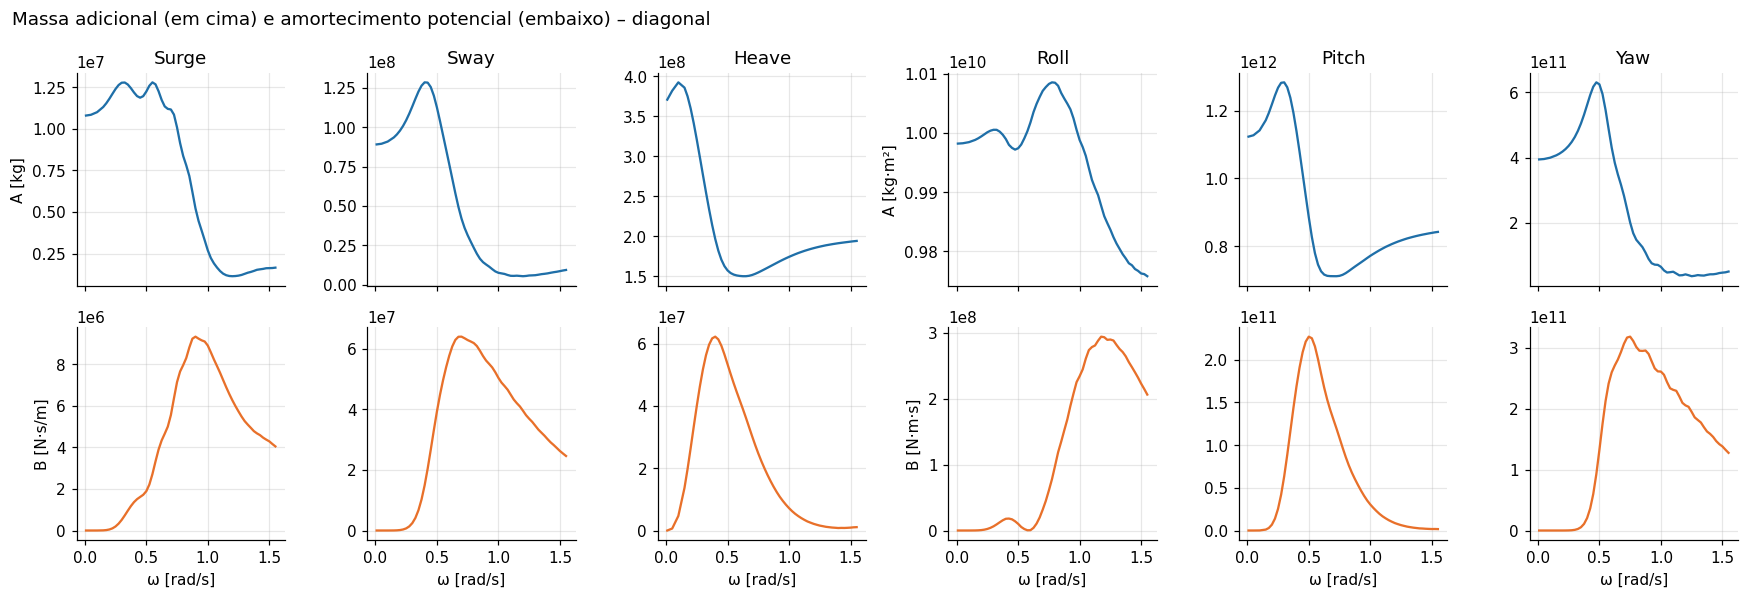

In [12]:
def diag(da, dof):
    return da.sel(radiating_dof=dof, influenced_dof=dof)

fig, axs = plt.subplots(2, 6, figsize=(16, 5.5), sharex=True)
for k, dof in enumerate(DOFS):
    u = 'kg·m²' if dof in ROT else 'kg'
    axs[0, k].plot(ds.omega, diag(ds.added_mass, dof), color='#1F6FA8')
    axs[0, k].set_title(dof)
    axs[0, k].set_ylabel(f'A [{u}]' if k in (0, 3) else '')
    axs[1, k].plot(ds.omega, diag(ds.radiation_damping, dof), color='#E8702A')
    axs[1, k].set_ylabel(('B [' + ('N·m·s' if dof in ROT else 'N·s/m') + ']') if k in (0, 3) else '')
    axs[1, k].set_xlabel('ω [rad/s]')
fig.suptitle('Massa adicional (em cima) e amortecimento potencial (embaixo) – diagonal', x=0.01, ha='left')
fig.tight_layout(); plt.show()

## 6. RAOs nos 6 graus de liberdade (só amortecimento potencial)

Para cada frequência e direção, o RAO vem do sistema linear 6 × 6

$$\left[-\omega^2\big(\mathbf{M}+\mathbf{A}(\omega)\big) - i\omega\big(\mathbf{B}(\omega)+\mathbf{B}_{ext}\big) + \mathbf{C} + \mathbf{C}_{ext}\right]\boldsymbol{\xi}(\omega,\beta) = \mathbf{F}(\omega,\beta)$$

e `cpt.post_pro.rao` resolve esse sistema usando `inertia_matrix` e `hydrostatic_stiffness` do dataset. Nesta seção **B_ext = 0**: só há o amortecimento potencial calculado pelo BEM.

Unidades: m/m nas translações e rad/m nas rotações (nos gráficos convertemos para °/m).

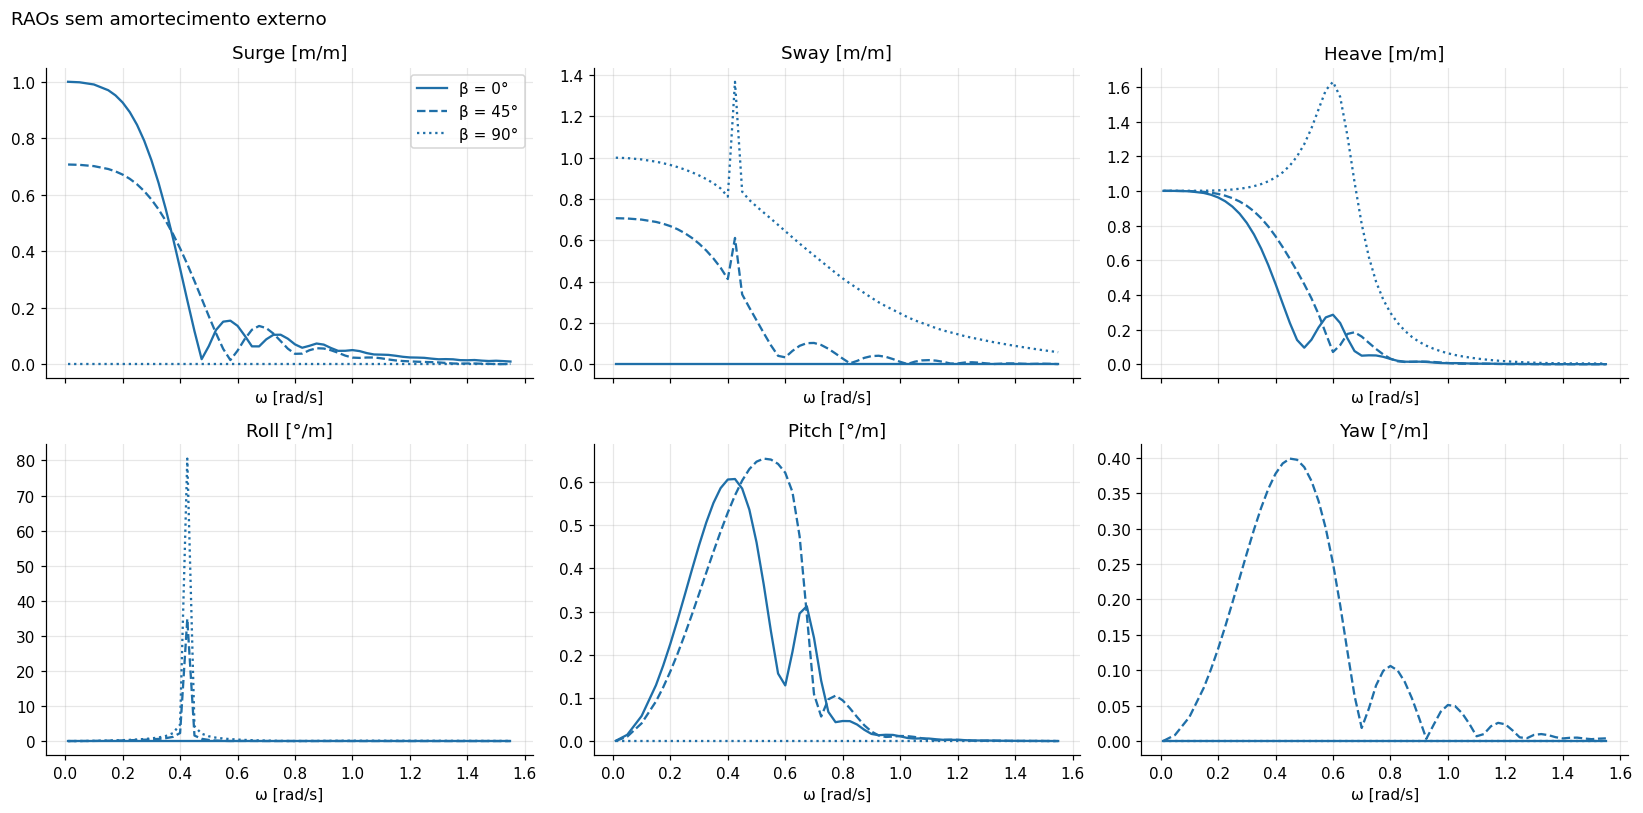

In [13]:
def em_unidades(dof, x):
    # rad/m -> °/m nas rotações
    return np.degrees(x) if dof in ROT else x

def rotulo(dof):
    return f'{dof} [°/m]' if dof in ROT else f'{dof} [m/m]'

def sel_beta(da, beta_graus):
    return da.sel(wave_direction=np.radians(beta_graus), method='nearest')

rao_pot = cpt.post_pro.rao(ds)        # dims: omega × wave_direction × radiating_dof
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for ax, dof in zip(axs.flat, DOFS):
    for b, ls in zip([0, 45, 90], ['-', '--', ':']):
        r = sel_beta(rao_pot, b).sel(radiating_dof=dof)
        ax.plot(ds.omega, em_unidades(dof, np.abs(r)), ls, color='#1F6FA8', label=f'β = {b}°')
    ax.set_title(rotulo(dof)); ax.set_xlabel('ω [rad/s]')
axs[0, 0].legend()
fig.suptitle('RAOs sem amortecimento externo', x=0.01, ha='left')
fig.tight_layout(); plt.show()

**Frequências naturais.** Heave, roll e pitch têm restauração hidrostática; a frequência natural é a raiz de C_ii − ω²(M_ii + A_ii(ω)) = 0. Surge, sway e yaw não têm rigidez (o FPSO está livre, sem ancoragem) e, portanto, não têm frequência natural.

In [14]:
def freq_natural(ds, dof):
    w = ds.omega.values
    A = diag(ds.added_mass, dof).values
    M = ds.inertia_matrix.sel(influenced_dof=dof, radiating_dof=dof).item()
    C = ds.hydrostatic_stiffness.sel(influenced_dof=dof, radiating_dof=dof).item()
    f = C - w**2 * (M + A)
    i = np.where(np.diff(np.sign(f)) != 0)[0][0]
    wn = w[i] - f[i] * (w[i+1] - w[i]) / (f[i+1] - f[i])
    return wn, np.interp(wn, w, A), np.interp(wn, w, diag(ds.radiation_damping, dof).values)

linhas = []
for dof in ['Heave', 'Roll', 'Pitch']:
    wn, An, Bn = freq_natural(ds, dof)
    Mii = ds.inertia_matrix.sel(influenced_dof=dof, radiating_dof=dof).item()
    Cii = ds.hydrostatic_stiffness.sel(influenced_dof=dof, radiating_dof=dof).item()
    zeta = Bn / (2 * np.sqrt(Cii * (Mii + An)))
    linhas.append([dof, wn, 2 * np.pi / wn, An / Mii, 100 * zeta])
naturais = pd.DataFrame(linhas, columns=['GL', 'ωn [rad/s]', 'Tn [s]', 'A/M em ωn', 'ζ potencial [%]']).set_index('GL')
naturais.style.format('{:.3f}')

,ωn [rad/s],Tn [s],A/M em ωn,ζ potencial [%]
GL,,,,
Heave,0.606,10.364,1.223,12.390
Roll,0.423,14.839,0.414,0.063
Pitch,0.658,9.553,1.483,9.526


Note o **amortecimento potencial de roll**: menos de 0,1% do crítico. Sem outra fonte de amortecimento, o RAO de roll em mar de través fica enorme perto de Tn. Na prática, o amortecimento de roll é dominado por efeitos **viscosos** (bolinas, quinas do casco, desprendimento de vórtices), que a teoria potencial não representa. Por isso ele é inserido como um **amortecimento externo**.

## 7. Inserindo um amortecimento externo no roll

O amortecimento externo é uma matriz 6 × 6, **B_ext**, somada a B(ω) na equação de movimento. Para o roll, é comum especificá-lo como uma fração ζ do amortecimento crítico:

$$B_{44}^{ext} = \zeta \, B_{44}^{crit} = 2\,\zeta\,\sqrt{C_{44}\,\big(I_{44}+A_{44}(\omega_{n})\big)}$$

**Passo a passo**

1. calcular ωn e A₄₄(ωn) (já feito na seção 6);
2. calcular B₄₄ para o ζ desejado;
3. montar a matriz B_ext com B₄₄ na posição (Roll, Roll) e zeros no resto;
4. passar a matriz em `cpt.post_pro.rao(ds, dissipation=B_ext)`.

In [15]:
def amortecimento_roll(ds, zeta):
    # B44 externo [N·m·s/rad] para uma fração zeta do amortecimento crítico de roll
    wn, A44, _ = freq_natural(ds, 'Roll')
    I44 = ds.inertia_matrix.sel(influenced_dof='Roll', radiating_dof='Roll').item()
    C44 = ds.hydrostatic_stiffness.sel(influenced_dof='Roll', radiating_dof='Roll').item()
    return 2 * zeta * np.sqrt(C44 * (I44 + A44))

def matriz_amortecimento(corpo, **termos):
    # matriz 6x6 rotulada, ex.: matriz_amortecimento(corpo, Roll=1e9)
    Bm = np.zeros((6, 6))
    for dof, valor in termos.items():
        i = DOFS.index(dof)
        Bm[i, i] = valor
    return corpo.add_dofs_labels_to_matrix(Bm)

ZETA_ROLL = 0.05                                   # 5% do crítico
B44 = amortecimento_roll(ds, ZETA_ROLL)
B_ext = matriz_amortecimento(corpo, Roll=B44)
print(f'B44 externo para ζ = {100 * ZETA_ROLL:.0f}%: {B44:.4e} N·m·s/rad')
B_ext

B44 externo para ζ = 5%: 1.4435e+09 N·m·s/rad


<xarray.DataArray (influenced_dof: 6, radiating_dof: 6)> Size: 288B
array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.44351884e+09,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00]])
Coordinates:
  * influenced_dof  (influenced_dof) <U5 120B 'Surge' 'Sway' ... 'Pitch' 'Yaw'
  * radiating_dof   (radiating_dof) <U5 120B 'Surge' 'Sway' ... 'Pitch' 'Yaw'

Agora o efeito no RAO de roll em **mar de través (β = 90°)** para quatro níveis de amortecimento externo:

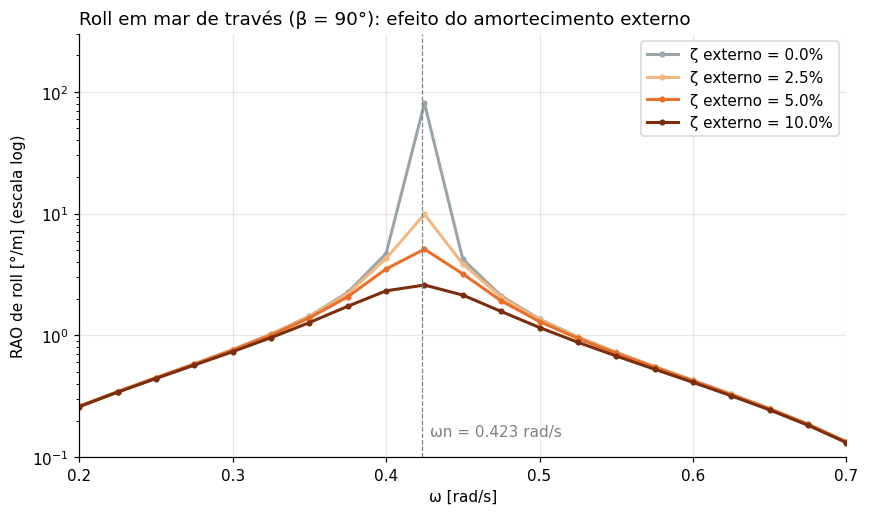

,ζ externo [%],pico do RAO [°/m],ω do pico [rad/s]
0,0.000,80.527,0.425
1,2.500,9.883,0.425
2,5.000,5.103,0.425
3,10.000,2.591,0.425


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
resumo = []
for zeta, cor in zip([0.0, 0.025, 0.05, 0.10], ['#9AA5AB', '#F2B880', '#E8702A', '#7A2E0E']):
    Bz = matriz_amortecimento(corpo, Roll=amortecimento_roll(ds, zeta))
    r = sel_beta(cpt.post_pro.rao(ds, dissipation=Bz), 90).sel(radiating_dof='Roll')
    r_deg = np.degrees(np.abs(r.values))
    ax.semilogy(ds.omega, r_deg, 'o-', ms=3, lw=2, color=cor, label=f'ζ externo = {100*zeta:.1f}%')
    resumo.append([100 * zeta, r_deg.max(), ds.omega.values[r_deg.argmax()]])
wn_roll = naturais.loc['Roll', 'ωn [rad/s]']
ax.axvline(wn_roll, color='gray', lw=0.8, ls='--')
ax.text(wn_roll + 0.005, 0.15, f'ωn = {wn_roll:.3f} rad/s', color='gray')
ax.set_xlabel('ω [rad/s]'); ax.set_ylabel('RAO de roll [°/m] (escala log)')
ax.set_title('Roll em mar de través (β = 90°): efeito do amortecimento externo', loc='left')
ax.set_xlim(0.2, 0.7); ax.set_ylim(0.1, 300); ax.legend(); plt.show()

pd.DataFrame(resumo, columns=['ζ externo [%]', 'pico do RAO [°/m]', 'ω do pico [rad/s]']).style.format('{:.3f}')

**Leitura.** O amortecimento externo quase não muda o RAO longe da ressonância, mas controla o pico: perto de ωn a resposta é limitada só pelo amortecimento. Sem amortecimento externo o pico atinge dezenas de graus por metro de amplitude, valor fisicamente irreal; com 5% do crítico ele cai para poucos graus por metro. (O eixo vertical está em escala logarítmica. Como as frequências estão espaçadas de 0,025 rad/s, o pico sem amortecimento externo é só indicativo: ele depende de quão perto de ωn cai a frequência calculada.)

**Outras formas de usar `dissipation`**
- Amortecimento em vários graus de liberdade ao mesmo tempo: `matriz_amortecimento(corpo, Roll=B44, Pitch=B55)`.
- Rigidez externa (por exemplo, a de um sistema de ancoragem): argumento `stiffness` de `cpt.post_pro.rao`, também como matriz 6 × 6 rotulada.

## 8. Comparação dos RAOs nos seis graus de liberdade

Daqui em diante usamos o modelo completo: amortecimento potencial + **5% do crítico em roll** (matriz `B_ext` da seção 7). Comparamos os seis RAOs para cinco direções de onda entre 0° (onda de popa para proa) e 90° (mar de través). Por causa da simetria do casco, as direções entre 90° e 360° repetem essas amplitudes (veja a tabela da seção 8.2).

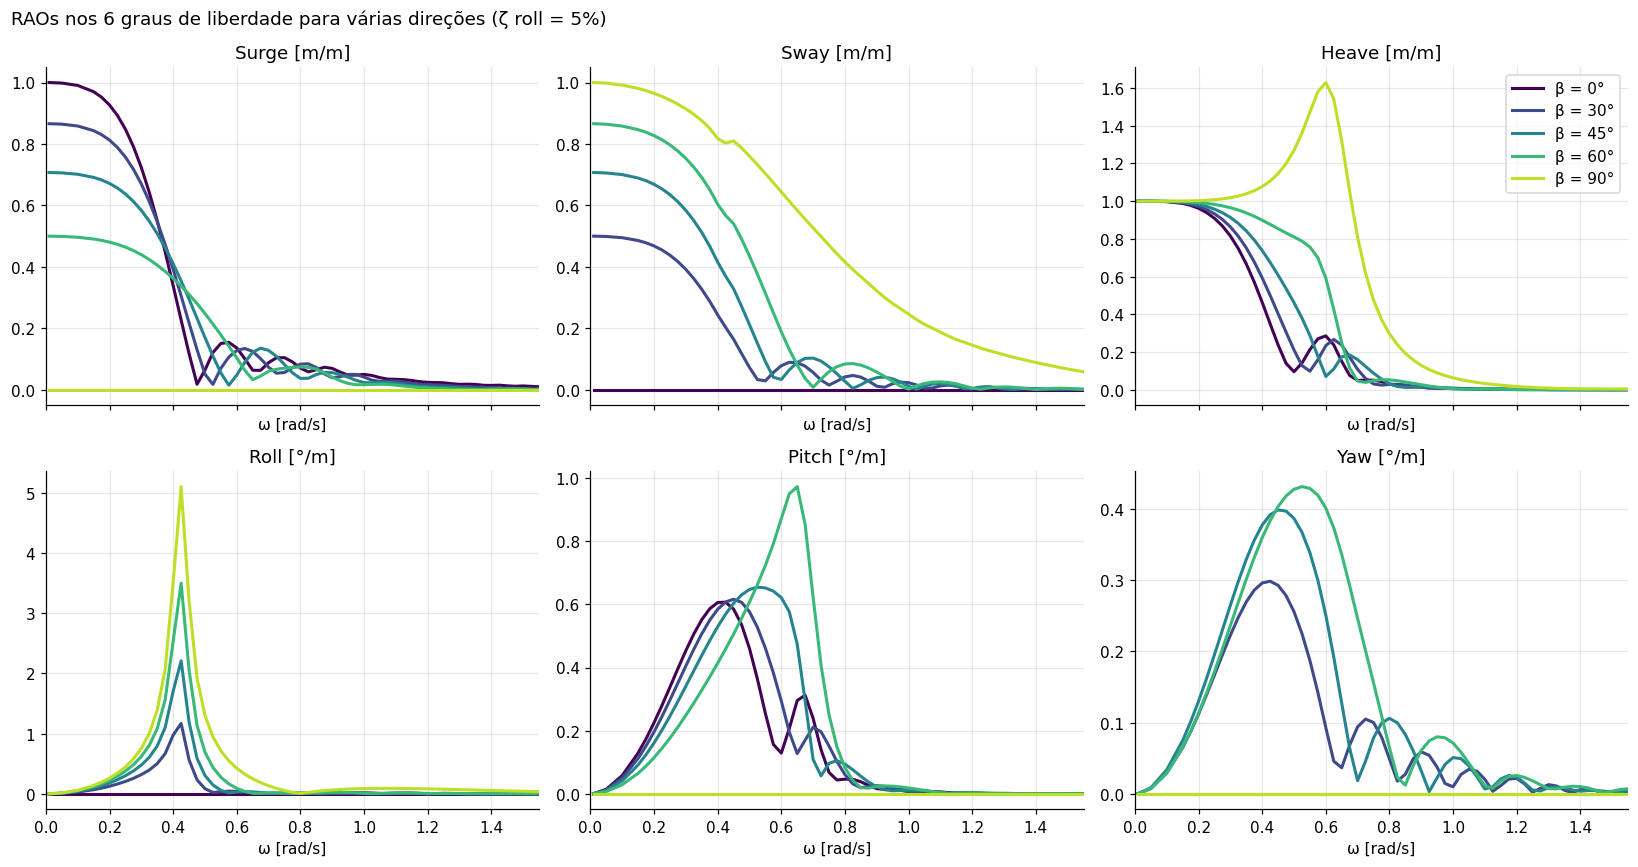

In [17]:
rao = cpt.post_pro.rao(ds, dissipation=B_ext)
direcoes = [b for b in [0, 30, 45, 60, 90] if np.isclose(betas, b).any()]
cores = plt.cm.viridis(np.linspace(0, 0.9, len(direcoes)))

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, dof in zip(axs.flat, DOFS):
    for b, cor in zip(direcoes, cores):
        r = em_unidades(dof, np.abs(sel_beta(rao, b).sel(radiating_dof=dof).values))
        ax.plot(ds.omega, r, lw=2, color=cor, label=f'β = {b}°')
    ax.set_title(rotulo(dof)); ax.set_xlabel('ω [rad/s]'); ax.set_xlim(0, omegas.max())
axs[0, 2].legend()
fig.suptitle(f'RAOs nos 6 graus de liberdade para várias direções (ζ roll = {100 * ZETA_ROLL:.0f}%)', x=0.01, ha='left')
fig.tight_layout(); plt.show()

**O que observar**
- **Simetria do casco:** em β = 0° sway, roll e yaw são nulos; em mar de través (90°), surge, pitch e yaw são nulos. Nas direções oblíquas os seis movimentos aparecem.
- **Translações horizontais (surge e sway):** tendem a 1 m/m para ondas longas, na projeção da direção de onda (cos β e sen β): o casco acompanha o movimento orbital das partículas.
- **Heave:** em mar de través o RAO passa de 1 perto de ωn, porque a força de excitação não é cancelada ao longo do comprimento como em mar de proa.
- **Roll:** o maior RAO é em mar de través, perto de ωn de roll, e diminui à medida que a onda fica mais alinhada com o casco.
- **Pitch:** o maior RAO não é em mar de proa, e sim em direções oblíquas (por volta de 60°), perto de ωn de pitch.

### 8.1 Mapa do RAO em função da frequência e da direção

Um mapa de cores mostra de uma vez todas as direções calculadas. Aqui, para heave, roll e pitch:

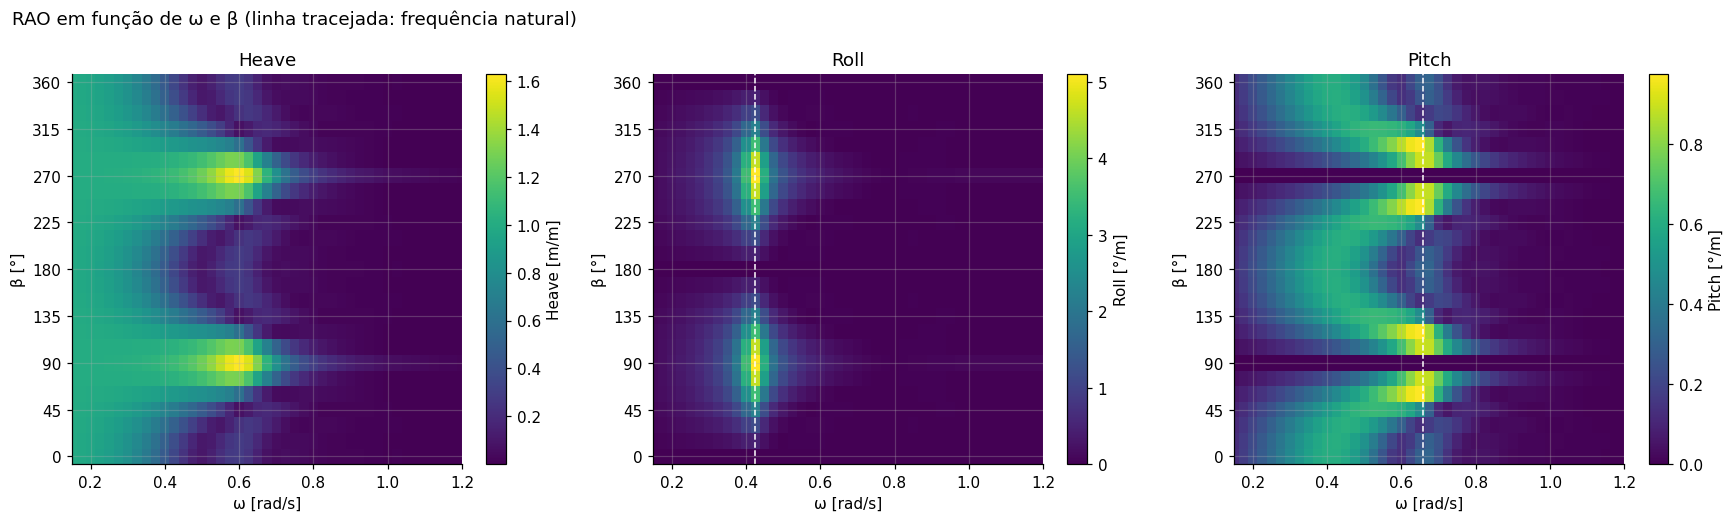

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
ordem = np.argsort(rao.wave_direction.values)
bdeg = np.degrees(rao.wave_direction.values[ordem])
for ax, dof in zip(axs, ['Heave', 'Roll', 'Pitch']):
    Z = em_unidades(dof, np.abs(rao.sel(radiating_dof=dof).values[:, ordem]))
    im = ax.pcolormesh(ds.omega, bdeg, Z.T, shading='nearest', cmap='viridis')
    fig.colorbar(im, ax=ax, label=rotulo(dof))
    ax.set_xlabel('ω [rad/s]'); ax.set_ylabel('β [°]'); ax.set_title(dof)
    ax.set_xlim(0.15, 1.2); ax.set_yticks(range(0, 361, 45))
    if dof in ('Roll', 'Pitch'):
        wn, _, _ = freq_natural(ds, dof)
        ax.axvline(wn, color='white', ls='--', lw=1)
fig.suptitle('RAO em função de ω e β (linha tracejada: frequência natural)', x=0.01, ha='left')
fig.tight_layout(); plt.show()

### 8.2 Resumo numérico

Para cada direção, o valor máximo do RAO de cada grau de liberdade na faixa calculada. Respostas nulas por simetria (menores que 0,001) aparecem como "—". Repare que 0° e 180°, e 45° e 135°, dão os mesmos valores: o casco é simétrico proa–popa.

In [ ]:
linhas = []
for b in [b for b in [0, 45, 90, 135, 180] if np.isclose(betas, b).any()]:
    linha = {'β [°]': b}
    for dof in DOFS:
        r = em_unidades(dof, np.abs(sel_beta(rao, b).sel(radiating_dof=dof).values))
        linha[rotulo(dof)] = r.max() if r.max() >= 1e-3 else np.nan
    linhas.append(linha)
pd.DataFrame(linhas).set_index('β [°]').style.format('{:.3f}', na_rep='—')

In [ ]:
naturais.style.format('{:.3f}')

## 9. Resumo e exercícios propostos

**Resumo**
- O modelo inteiro (frequências, direções, massa, inércias e amortecimento externo) é definido por vetores e matrizes no próprio notebook; só a geometria vem de um arquivo (`ship_low.gdf`).
- O roll é o grau de liberdade mais sensível: o amortecimento potencial é pequeno e o pico do RAO depende quase só do amortecimento externo, que precisa ser estimado à parte (ensaio de decaimento, métodos empíricos como o de Ikeda).
- Surge, sway e yaw não têm restauração; sem ancoragem, suas respostas crescem para ondas longas.

**Exercícios**
1. Mude o raio de giração de pitch (k_yy) para 0,22 L e 0,28 L na seção 1.2. Como mudam Tn e o RAO de pitch? Não é preciso refazer o cálculo BEM: só a massa muda (rode a partir da seção 3).
2. Repita a seção 7 com ζ = 10% e 15% e trace o pico do RAO de roll em função de ζ.
3. Troque a formulação para `cpt.BEMSolver(method='indirect')` e compare a massa adicional de roll com a da formulação direta.
4. Gere uma malha própria com `cpt.mesh_parallelepiped` (como na Aula 09) e compare com a malha do arquivo GDF. Quantos painéis são necessários para os resultados mudarem menos de 1%?
5. Adicione uma rigidez de ancoragem em surge e sway com o argumento `stiffness` de `cpt.post_pro.rao` e observe o aparecimento de frequências naturais horizontais.